In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from svm_margin_plot import plot_svm_boundary

In [3]:
df = pd.read_csv('mouse_viral_study.csv')

In [4]:
df.head()

,Med_1_mL,Med_2_mL,Virus Present
0,6.508231,8.582531,0
1,4.126116,3.073459,1
2,6.427870,6.369758,0
3,3.672953,4.905215,1
4,1.580321,2.440562,1


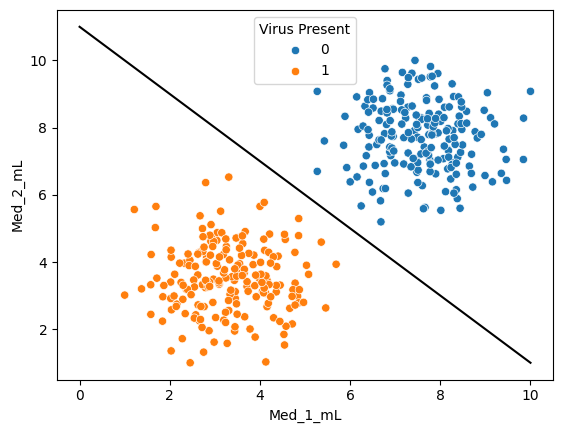

In [8]:
sns.scatterplot(x='Med_1_mL', y='Med_2_mL', hue='Virus Present', data=df)

X = np.linspace(0,10,100)
m = -1
b = 11
y = m*X + b

plt.plot(X, y, 'black')

In [9]:
from sklearn.svm import SVC

In [10]:
help(SVC)

Help on class SVC in module sklearn.svm._classes:

class SVC(sklearn.svm._base.BaseSVC)
 |  SVC(*, C=1.0, kernel='rbf', degree=3, gamma='scale', coef0=0.0, shrinking=True, probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=None)
 |
 |  C-Support Vector Classification.
 |
 |  The implementation is based on libsvm. The fit time scales at least
 |  quadratically with the number of samples and may be impractical
 |  beyond tens of thousands of samples. For large datasets
 |  consider using :class:`~sklearn.svm.LinearSVC` or
 |  :class:`~sklearn.linear_model.SGDClassifier` instead, possibly after a
 |  :class:`~sklearn.kernel_approximation.Nystroem` transformer or
 |  other :ref:`kernel_approximation`.
 |
 |  The multiclass support is handled according to a one-vs-one scheme.
 |
 |  For details on the precise mathematical formulation of the provided
 |  kernel functions and how `gamma`, `

In [11]:
y = df['Virus Present']

In [12]:
X = df.drop('Virus Present', axis=1)

In [33]:
model = SVC(kernel='linear', C=1000) # линейное ядро модели, разделяем модель линией для будущей класификации
model.fit(X, y)

,C,1000
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


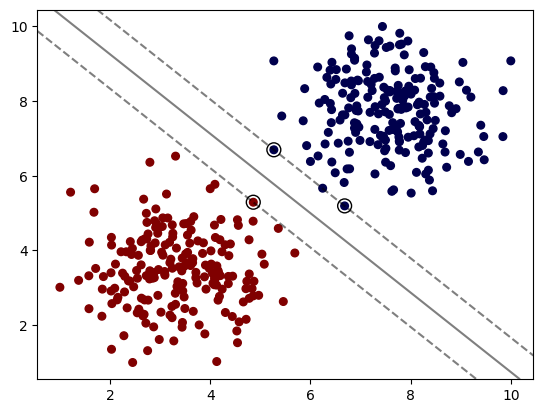

In [16]:
plot_svm_boundary(model, X, y)

In [34]:
model = SVC(kernel='linear', C=0.05)
# C это сложность модели, чем больше значение - тем меньше штраф (модель может недообучиться),
# чем меньше - тем строже модель и если переборщить будет переобучена, в любом случае лучше перебрать по сетке.
# Формула такая α = 1/C; 1 / 0.05 = 20

In [18]:
model.fit(X, y)

,C,0.05
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


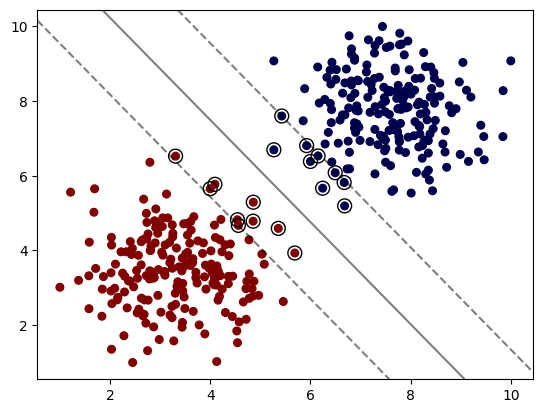

In [19]:
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


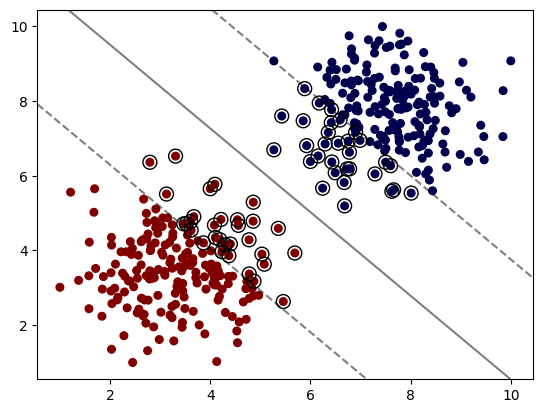

In [21]:
model = SVC(kernel='linear', C=0.005)
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


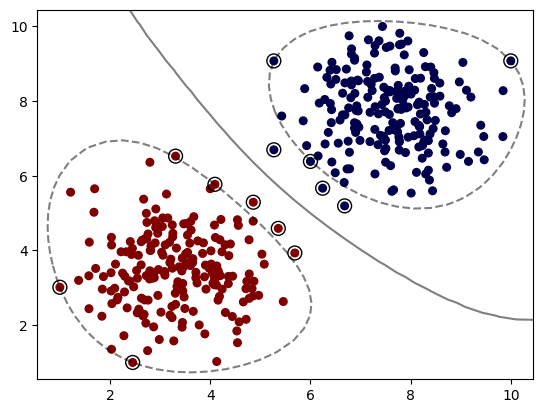

In [37]:
model = SVC(kernel='rbf', C=1) # кроме линейного разделения признаков появляются области расположения признаков
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


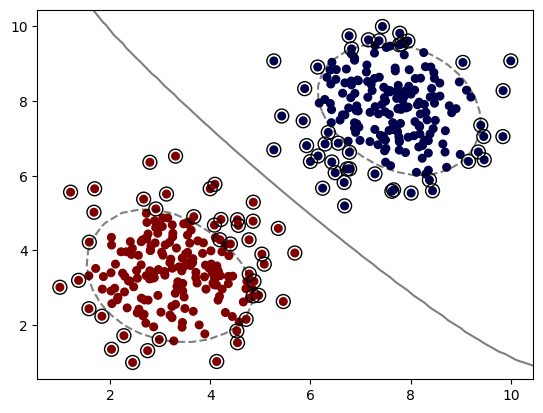

In [36]:
model = SVC(kernel='rbf', C=0.05) 
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


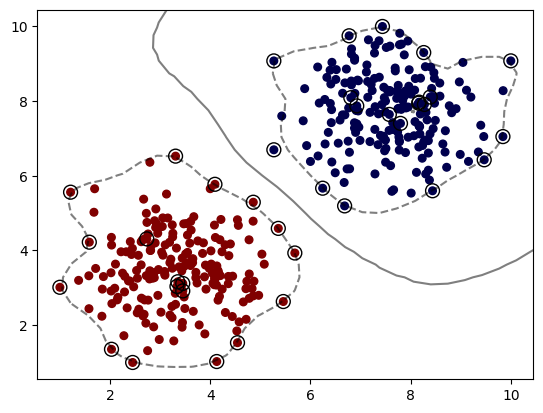

In [35]:
model = SVC(kernel='rbf', C=1, gamma='auto') # по умолчанию это значение равно 1 / кол.во признаков, в нашем случае
# 1/2 = 0.5, сама по себе гамма влияет на чувствительность модели к границам данных
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


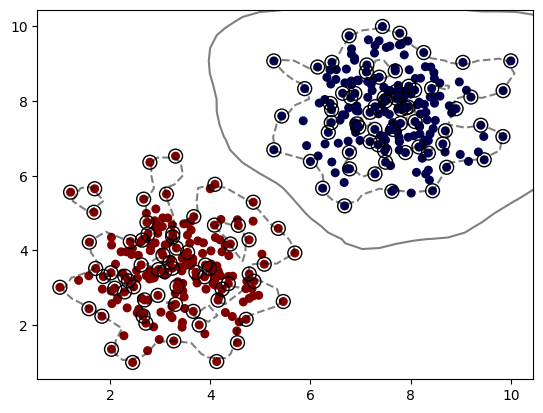

In [29]:
model = SVC(kernel='rbf', C=1, gamma=2) # видно что модель переобучена и на графике полная белеберда, модель слишком сильно подгоняется
# под значения данные
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


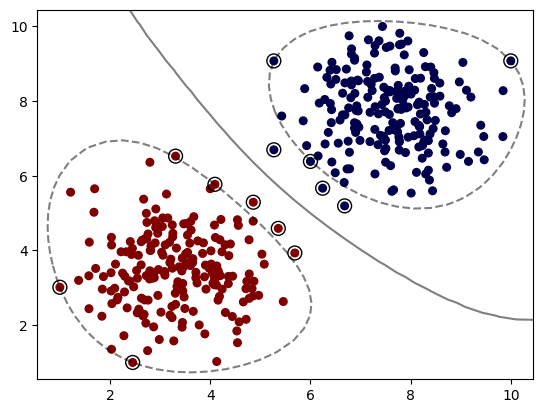

In [30]:
model = SVC(kernel='rbf', C=1, gamma='scale') # лучше оставить гамма 'scale'
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


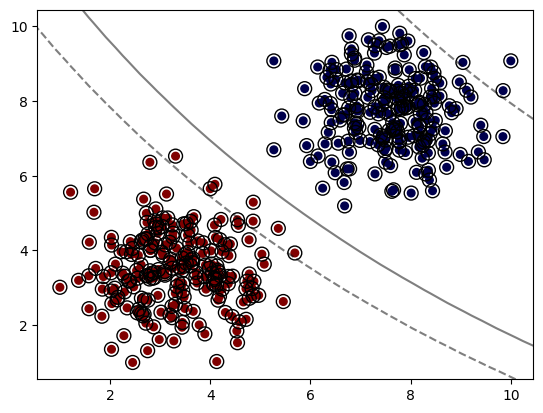

In [38]:
model = SVC(kernel='sigmoid') 
model.fit(X, y)
plot_svm_boundary(model, X, y)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


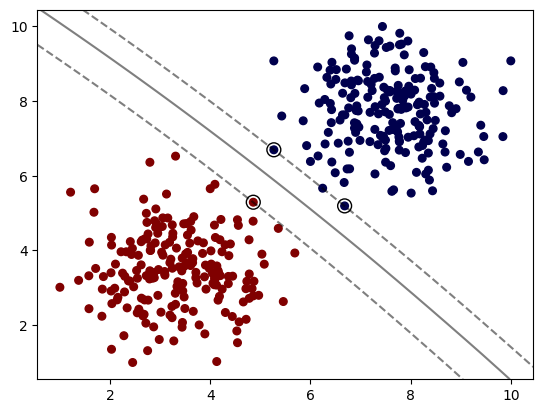

In [45]:
model = SVC(kernel='poly', degree=4, C=0.05)
model.fit(X, y)
plot_svm_boundary(model, X, y)

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
svm = SVC()

In [48]:
param_grid = {'C':[0.01,0.1,1], 'kernel':['linear', 'rbf']}

In [49]:
grid = GridSearchCV(svm, param_grid)

In [50]:
grid.fit(X,y)

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.01


In [51]:
grid.best_params_

{'C': 0.01, 'kernel': 'linear'}